# Assignment 5: Convolutional Neural Network

Alexa Rodríguez Méndez 2133921 - Thursday N4

José Omar de Anda Garza 2012643 - Tuesday N4


## 1. Load libraries

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load data

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train data shape: (60000, 28, 28)
Train labels shape: (60000,)
Test data shape: (10000, 28, 28)
Test labels shape: (10000,)


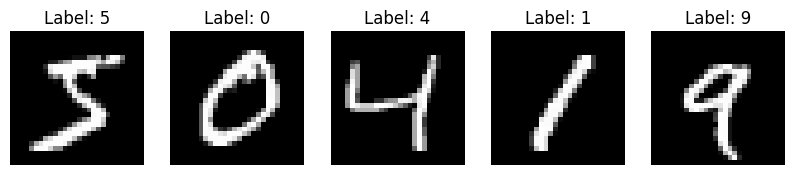

In [2]:
(train_data, train_labels), (test_data, test_labels) = mnist.load_data()

print("Train data shape:", train_data.shape)
print("Train labels shape:", train_labels.shape)
print("Test data shape:", test_data.shape)
print("Test labels shape:", test_labels.shape)

# Ejemplos del dataset
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(train_data[i], cmap="gray")
    plt.title(f"Label: {train_labels[i]}")
    plt.axis("off")
plt.show()

## 3. Data preprocessing

In [3]:
# Normalizar los pixeles a [0, 1]
train_data = train_data.astype("float32") / 255.0
test_data = test_data.astype("float32") / 255.0

# Agregar canal (las CNN esperan (alto, ancho, canales))
train_data = np.expand_dims(train_data, -1)
test_data = np.expand_dims(test_data, -1)

print("Train data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

Train data shape: (60000, 28, 28, 1)
Test data shape: (10000, 28, 28, 1)


## 4. Model selection and training

In [4]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_data, train_labels,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 50ms/step - accuracy: 0.9425 - loss: 0.1920 - val_accuracy: 0.9833 - val_loss: 0.0566
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 53ms/step - accuracy: 0.9825 - loss: 0.0557 - val_accuracy: 0.9882 - val_loss: 0.0453
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9879 - loss: 0.0392 - val_accuracy: 0.9895 - val_loss: 0.0374
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9906 - loss: 0.0281 - val_accuracy: 0.9893 - val_loss: 0.0385
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9926 - loss: 0.0232 - val_accuracy: 0.9868 - val_loss: 0.0440
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9947 - loss: 0.0170 - val_accuracy: 0.9907 - val_loss: 0.0390
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9946 - loss: 0.0164 - val_accuracy: 0.9907 - val_loss: 0.0368
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 48ms/step - accuracy: 0.9966 - loss: 0.0108 - 

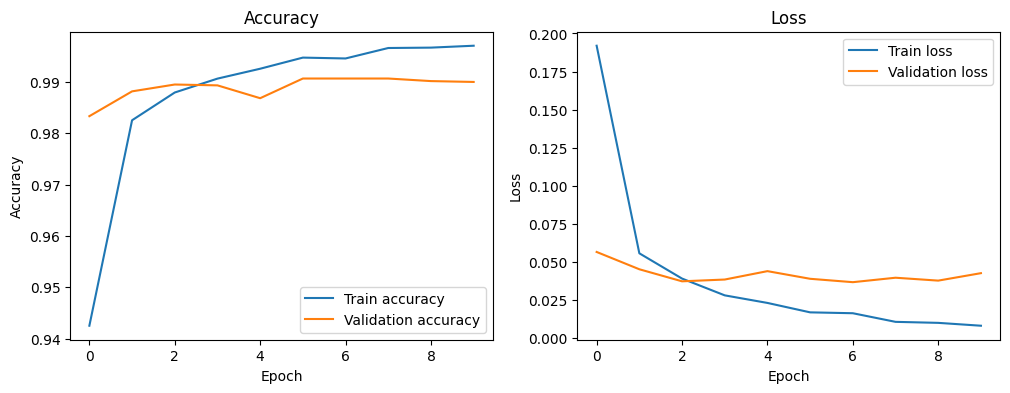

In [6]:
# Curvas de entrenamiento
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Loss")

plt.show()

## 5. Model testing

In [7]:
test_loss, test_acc = model.evaluate(test_data, test_labels, verbose=2)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

313/313 - 2s - 7ms/step - accuracy: 0.9912 - loss: 0.0347
Test loss: 0.0347
Test accuracy: 0.9912 (99.12%)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
Imagen 1: Predicción = 7 | Valor real = 7
Imagen 2: Predicción = 2 | Valor real = 2
Imagen 3: Predicción = 1 | Valor real = 1
Imagen 4: Predicción = 0 | Valor real = 0
Imagen 5: Predicción = 4 | Valor real = 4


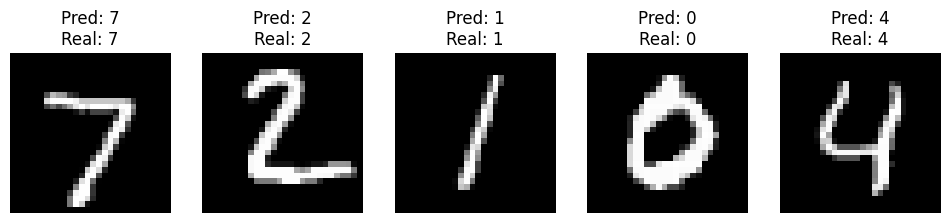

In [8]:
# 5 predicciones distintas del conjunto de prueba
predictions = model.predict(test_data[:5])

plt.figure(figsize=(12, 3))
for i in range(5):
    predicted = np.argmax(predictions[i])
    actual = test_labels[i]
    print(f"Imagen {i+1}: Predicción = {predicted} | Valor real = {actual}")
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_data[i].reshape(28, 28), cmap="gray")
    plt.title(f"Pred: {predicted}\nReal: {actual}")
    plt.axis("off")
plt.show()